# PUSL3123 Assessment 1 - Exercise 1: MLP on CIFAR-10

Group: AI-ML Assessment 1 | Notebook by: Nethsara BD

Goal: train an MLP with 3 trainable layers on CIFAR-10 and report train, validation and test results with loss plots.

The test set is only used once, in section 13. It is not used for tuning.

## 2. Imports and settings
All the settings are in one cell so the whole group can use the same ones.

In [1]:
import sys, time, random, hashlib
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.datasets as datasets
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, Subset

# group settings
SEED        = 42
BATCH_SIZE  = 128
EPOCHS      = 20
LEARNING_RATE = 1e-3
WEIGHT_DECAY  = 0.0
VAL_SIZE    = 5000            # from train set only
NUM_WORKERS = 2
DATA_DIR    = "./data"

# normalisation values
CIFAR_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR_STD  = (0.2470, 0.2435, 0.2616)

CLASS_NAMES = ["aeroplane", "automobile", "bird", "cat", "deer",
               "dog", "frog", "horse", "ship", "truck"]

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Python {sys.version.split()[0]} | PyTorch {torch.__version__} | torchvision {torchvision.__version__}")
print(f"Device: {device}")

Python 3.13.18 | PyTorch 2.14.1+cpu | torchvision 0.29.1+cpu
Device: cpu


## 3. Seeds
Setting the seed so the split and training give the same results each run.

In [2]:
def set_seed(seed: int = SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)
print(f"Seed set to {SEED}")

Seed set to 42


## 4. Load CIFAR-10
Using the official train (50,000) and test (10,000) sets from torchvision.

## 5. Train/validation split
The 50,000 training images are split into 45,000 train and 5,000 validation using the seed. The test set is not touched.

In [3]:
# no augmentation here
base_transform = transforms.Compose([
    transforms.ToTensor(),                              # image to tensor
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD),        # normalise
])
train_transform = base_transform   # ex 3 changes this one
eval_transform  = base_transform   # keep val/test fixed

# load data
full_train_for_train = datasets.CIFAR10(DATA_DIR, train=True,  download=True, transform=train_transform)
full_train_for_val   = datasets.CIFAR10(DATA_DIR, train=True,  download=True, transform=eval_transform)
test_dataset         = datasets.CIFAR10(DATA_DIR, train=False, download=True, transform=eval_transform)

# 45k train / 5k val split
split_generator = torch.Generator().manual_seed(SEED)
perm = torch.randperm(len(full_train_for_train), generator=split_generator).numpy()
val_indices   = np.sort(perm[:VAL_SIZE])
train_indices = np.sort(perm[VAL_SIZE:])

train_dataset      = Subset(full_train_for_train, train_indices.tolist())
validation_dataset = Subset(full_train_for_val,   val_indices.tolist())

# same value everywhere = same split
split_hash = hashlib.md5(val_indices.tobytes()).hexdigest()
print(f"Split seed: {SEED} | validation-index fingerprint (md5): {split_hash}")

100%|██████████| 170M/170M [00:04<00:00, 40.5MB/s]


Split seed: 42 | validation-index fingerprint (md5): d45cf7fe22a123b42b27274bddc38a8e


## 6. Data loaders
Train data is shuffled, validation and test are not.

In [4]:
def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

loader_generator = torch.Generator().manual_seed(SEED)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, worker_init_fn=seed_worker,
                          generator=loader_generator, pin_memory=(device.type == "cuda"))
validation_loader = DataLoader(validation_dataset, batch_size=BATCH_SIZE, shuffle=False,
                               num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"))
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"))

## 7. Sanity checks
Checking sizes, shapes and overlap before training.

Train / Val / Test sizes: 45000 / 5000 / 10000
Batch shape: (128, 3, 32, 32) | label dtype: torch.int64
Per-channel batch mean (should be near 0): [-0.039 -0.037 -0.034]
Per-channel batch std  (should be near 1): [1.016 1.017 1.003]
All sanity checks passed.


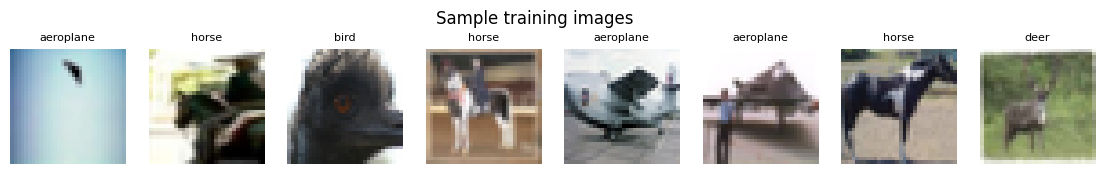

In [5]:
assert len(train_dataset) == 45000,      f"Train size is {len(train_dataset)}"
assert len(validation_dataset) == 5000,  f"Validation size is {len(validation_dataset)}"
assert len(test_dataset) == 10000,       f"Test size is {len(test_dataset)}"
assert len(set(train_indices) & set(val_indices)) == 0, "Train/validation overlap!"
assert len(train_indices) + len(val_indices) == 50000

images, labels = next(iter(train_loader))
assert images.shape == (BATCH_SIZE, 3, 32, 32), f"Unexpected batch shape {images.shape}"
assert labels.min() >= 0 and labels.max() <= 9, "Labels outside 0-9"
assert torch.isfinite(images).all(), "Non-finite pixel values"

print(f"Train / Val / Test sizes: {len(train_dataset)} / {len(validation_dataset)} / {len(test_dataset)}")
print(f"Batch shape: {tuple(images.shape)} | label dtype: {labels.dtype}")
print("Per-channel batch mean (should be near 0):", images.mean(dim=(0, 2, 3)).numpy().round(3))
print("Per-channel batch std  (should be near 1):", images.std(dim=(0, 2, 3)).numpy().round(3))
print("All sanity checks passed.")

# look at a few images
mean_t = torch.tensor(CIFAR_MEAN).view(3, 1, 1)
std_t  = torch.tensor(CIFAR_STD).view(3, 1, 1)
fig, axes = plt.subplots(1, 8, figsize=(14, 2))
for ax, img, lbl in zip(axes, images[:8], labels[:8]):
    ax.imshow((img * std_t + mean_t).clamp(0, 1).permute(1, 2, 0))
    ax.set_title(CLASS_NAMES[lbl], fontsize=8)
    ax.axis("off")
plt.suptitle("Sample training images")
plt.show()

## 8. MLP model
3 trainable layers: 3072 -> 512 -> 256 -> 10. Flatten and ReLU have no weights, so they don't count as layers. No softmax at the end because CrossEntropyLoss already does it.

In [6]:
class MLP(nn.Module):
    def __init__(self, in_features=3 * 32 * 32, hidden1=512, hidden2=256, num_classes=10):
        super().__init__()
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(in_features, hidden1)   # layer 1
        self.fc2 = nn.Linear(hidden1, hidden2)       # layer 2
        self.fc3 = nn.Linear(hidden2, num_classes)   # layer 3, outputs
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.flatten(x)
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        return self.fc3(x)

set_seed(SEED)                      # seed before building model
model = MLP().to(device)
print(model)

MLP(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=3072, out_features=512, bias=True)
  (fc2): Linear(in_features=512, out_features=256, bias=True)
  (fc3): Linear(in_features=256, out_features=10, bias=True)
  (relu): ReLU()
)


## 9. Parameter count
Counting all trainable weights. Same method will be used for the CNN.

In [7]:
def count_trainable_parameters(m: nn.Module) -> int:
    return sum(p.numel() for p in m.parameters() if p.requires_grad)

n_params = count_trainable_parameters(model)
trainable_layers = sum(1 for m in model.modules() if isinstance(m, nn.Linear))

# check by hand
manual = (3072*512 + 512) + (512*256 + 256) + (256*10 + 10)
assert n_params == manual
print(f"Trainable layers: {trainable_layers}")
print(f"Trainable parameters: {n_params:,}")

Trainable layers: 3
Trainable parameters: 1,707,274


## 10. Train and validation functions
Loss and accuracy are averaged over all images. Evaluation uses model.eval() and no_grad.

In [8]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)

def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)
    return total_loss / total, 100.0 * correct / total

@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        loss = criterion(outputs, labels)
        total_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)
    return total_loss / total, 100.0 * correct / total

## 11. Training
Train for 20 epochs and save the loss and accuracy each epoch. No test data here.

In [9]:
history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

start = time.time()
for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
    va_loss, va_acc = evaluate(model, validation_loader, criterion, device)

    history["train_loss"].append(tr_loss); history["train_acc"].append(tr_acc)
    history["val_loss"].append(va_loss);   history["val_acc"].append(va_acc)

    print(f"Epoch {epoch:02d}/{EPOCHS} | train loss {tr_loss:.4f} acc {tr_acc:5.2f}% "
          f"| val loss {va_loss:.4f} acc {va_acc:5.2f}%")
training_time = time.time() - start
print(f"\nTotal training time: {training_time:.1f}s on {device}")

Epoch 01/20 | train loss 1.6555 acc 41.50% | val loss 1.5274 acc 45.18%
Epoch 02/20 | train loss 1.4454 acc 49.03% | val loss 1.4402 acc 49.34%
Epoch 03/20 | train loss 1.3321 acc 53.16% | val loss 1.4458 acc 50.20%
Epoch 04/20 | train loss 1.2447 acc 56.30% | val loss 1.4062 acc 51.42%
Epoch 05/20 | train loss 1.1641 acc 59.06% | val loss 1.3942 acc 51.48%
Epoch 06/20 | train loss 1.0873 acc 61.54% | val loss 1.4004 acc 52.58%
Epoch 07/20 | train loss 1.0119 acc 64.18% | val loss 1.4417 acc 51.96%
Epoch 08/20 | train loss 0.9439 acc 66.68% | val loss 1.4765 acc 51.96%
Epoch 09/20 | train loss 0.8778 acc 68.91% | val loss 1.4695 acc 53.16%
Epoch 10/20 | train loss 0.8003 acc 71.51% | val loss 1.5768 acc 53.10%
Epoch 11/20 | train loss 0.7451 acc 73.57% | val loss 1.6181 acc 52.62%
Epoch 12/20 | train loss 0.6847 acc 75.64% | val loss 1.7101 acc 53.38%
Epoch 13/20 | train loss 0.6306 acc 77.62% | val loss 1.7892 acc 53.24%
Epoch 14/20 | train loss 0.5739 acc 79.85% | val loss 1.8068 acc

## 12. Plots
Loss and accuracy for train vs validation.

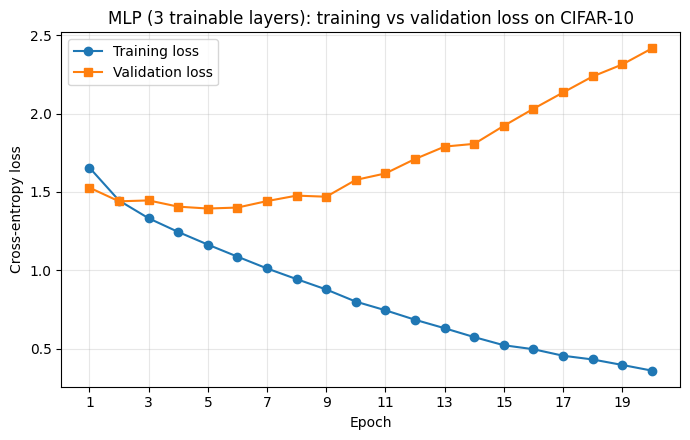

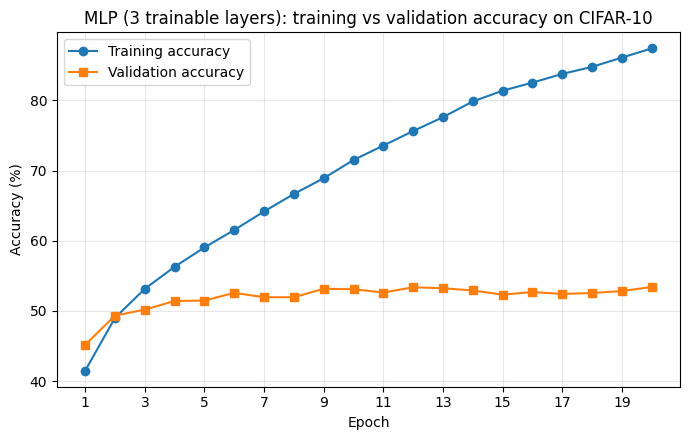

In [10]:
epochs_range = range(1, EPOCHS + 1)

# loss plot
plt.figure(figsize=(7, 4.5))
plt.plot(epochs_range, history["train_loss"], marker="o", label="Training loss")
plt.plot(epochs_range, history["val_loss"], marker="s", label="Validation loss")
plt.xlabel("Epoch"); plt.ylabel("Cross-entropy loss")
plt.title("MLP (3 trainable layers): training vs validation loss on CIFAR-10")
plt.xticks(list(epochs_range)[::2]); plt.grid(alpha=0.3); plt.legend()
plt.tight_layout(); plt.savefig("mlp_loss_curve.png", dpi=200); plt.show()

# accuracy plot
plt.figure(figsize=(7, 4.5))
plt.plot(epochs_range, history["train_acc"], marker="o", label="Training accuracy")
plt.plot(epochs_range, history["val_acc"], marker="s", label="Validation accuracy")
plt.xlabel("Epoch"); plt.ylabel("Accuracy (%)")
plt.title("MLP (3 trainable layers): training vs validation accuracy on CIFAR-10")
plt.xticks(list(epochs_range)[::2]); plt.grid(alpha=0.3); plt.legend()
plt.tight_layout(); plt.savefig("mlp_accuracy_curve.png", dpi=200); plt.show()

## 13. Test evaluation
Final check on the test set, done once.

In [11]:
test_loss, test_acc = evaluate(model, test_loader, criterion, device)
print(f"Test loss: {test_loss:.4f} | Test accuracy: {test_acc:.2f}%")

Test loss: 2.4341 | Test accuracy: 52.87%


## 14. Results

In [12]:
results = pd.DataFrame([{
    "Model": "MLP",
    "Trainable layers": trainable_layers,
    "Trainable parameters": n_params,
    "Train accuracy (%)": round(history["train_acc"][-1], 2),
    "Validation accuracy (%)": round(history["val_acc"][-1], 2),
    "Test accuracy (%)": round(test_acc, 2),
    "Final train loss": round(history["train_loss"][-1], 4),
    "Final validation loss": round(history["val_loss"][-1], 4),
    "Test loss": round(test_loss, 4),
    "Training time (s)": round(training_time, 1),
}])
display(results.T.rename(columns={0: "MLP"}))
results.to_csv("mlp_results.csv", index=False)

print("\nConfiguration used:")
print(f"seed={SEED}, batch_size={BATCH_SIZE}, epochs={EPOCHS}, optimiser=Adam, lr={LEARNING_RATE}, "
      f"weight_decay={WEIGHT_DECAY}, split=45000/5000/10000, device={device}")
print(f"Validation-index fingerprint: {split_hash}")

,MLP
Model,MLP
Trainable layers,3
Trainable parameters,1707274
Train accuracy (%),87.41
Validation accuracy (%),53.42
Test accuracy (%),52.87
Final train loss,0.3603
Final validation loss,2.4153
Test loss,2.4341
Training time (s),231.4



Configuration used:
seed=42, batch_size=128, epochs=20, optimiser=Adam, lr=0.001, weight_decay=0.0, split=45000/5000/10000, device=cpu
Validation-index fingerprint: d45cf7fe22a123b42b27274bddc38a8e


### Observations

- Training loss kept falling (0.36 at epoch 20), but validation loss went back up (2.42 at the end). That is overfitting.
- Train accuracy 87.41%, validation 53.42%, test 52.87%. The gap is about 35 points.
- The input is 3072 because a 32x32 image with 3 colour channels is 32*32*3 numbers. The output is 10 because there are 10 classes.
- Flattening turns the image into one long list, so the model doesn't know which pixels are next to each other.
- Limits: one run, one seed, 20 epochs, no tuning.